# Tutorial 14 (T14): Building Programs to Implement Random Forest Algorithm

## 📌 Objective
Implement a **Random Forest Classifier** ensemble on the crop dataset. Examine the effect of `n_estimators` (number of trees) on testing accuracy and **Out-of-Bag (OOB)** score, compare Random Forest vs single Decision Tree variance, and assess feature importances.

## 🔬 Key Concepts & Mathematical Formulas
- **Ensemble Learning (Bagging)**: Bootstrap Aggregation trains $B$ independent trees on random subsets with replacement:
  $$\hat{y} = \text{mode} \{ T_1(x), T_2(x), \dots, T_B(x) \}$$
- **Variance Reduction Principle**: If each tree has variance $\sigma^2$ with pairwise correlation $\rho$, ensemble variance is:
  $$\text{Var}(\bar{T}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$
- **Random Subspace Method**: Selects $m = \sqrt{p}$ random features at each split, de-correlating trees (reducing $\rho$).
- **Out-of-Bag (OOB) Score**: Validation accuracy evaluated on samples omitted from each tree's bootstrap sample (~36.8% of training data).

### Step 1: Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid", palette="muted")
print('Random Forest libraries loaded!')

Random Forest libraries loaded!


### Step 2: Load Data and Split (80/20)

In [2]:
df = pd.read_csv('data/Crop_recommendation.csv')
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[features]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f'Training Samples: {len(X_train)}, Testing Samples: {len(X_test)}')

Training Samples: 1760, Testing Samples: 440


### Step 3: Varying Number of Trees (`n_estimators`) vs OOB Score
We test tree counts from 10 to 200 and observe testing accuracy and Out-of-Bag score stabilization.

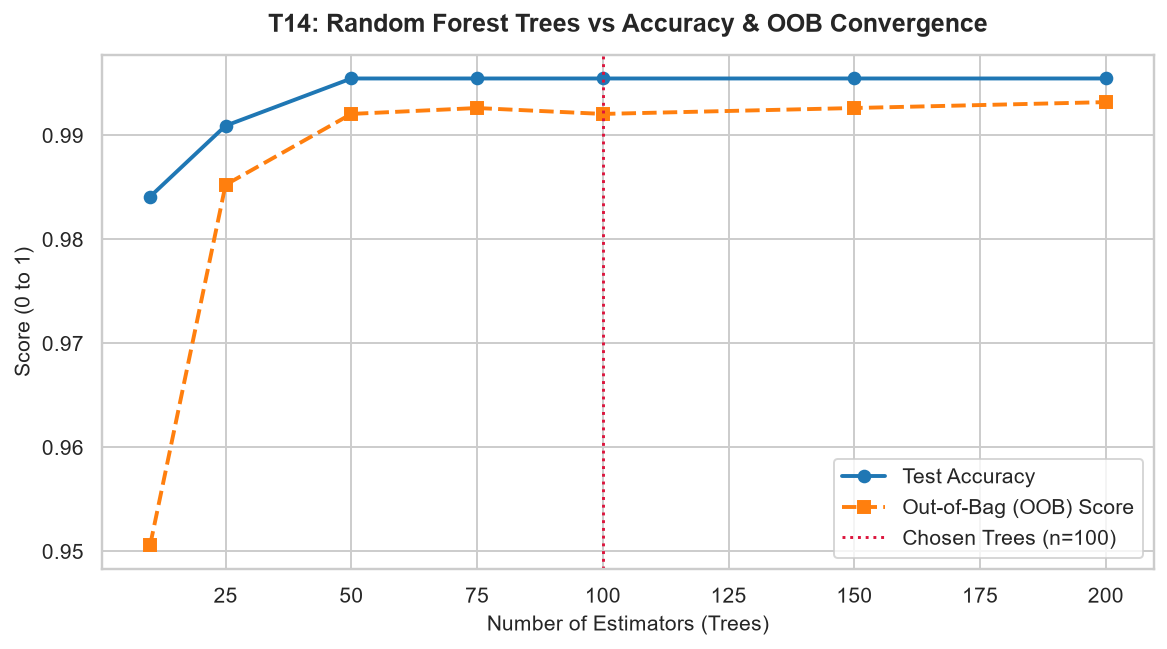

In [3]:
tree_counts = [10, 25, 50, 75, 100, 150, 200]
oob_scores = []
test_scores = []

for n in tree_counts:
    rf_temp = RandomForestClassifier(n_estimators=n, max_depth=8, oob_score=True, random_state=42)
    rf_temp.fit(X_train, y_train)
    oob_scores.append(rf_temp.oob_score_)
    test_scores.append(rf_temp.score(X_test, y_test))

plt.figure(figsize=(8.5, 4.8), dpi=140)
plt.plot(tree_counts, test_scores, 'o-', color='#1f77b4', linewidth=2, label='Test Accuracy')
plt.plot(tree_counts, oob_scores, 's--', color='#ff7f0e', linewidth=2, label='Out-of-Bag (OOB) Score')
plt.title('T14: Random Forest Trees vs Accuracy & OOB Convergence', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Number of Estimators (Trees)', fontsize=11)
plt.ylabel('Score (0 to 1)', fontsize=11)
plt.axvline(x=100, color='crimson', linestyle=':', label='Chosen Trees (n=100)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Step 4: Fit Optimized Random Forest Classifier ($n=100$)

In [4]:
rf = RandomForestClassifier(n_estimators=100, max_depth=8, oob_score=True, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

rf_train_acc = rf.score(X_train, y_train)
rf_test_acc = accuracy_score(y_test, y_pred_rf)
rf_oob = rf.oob_score_

print(f'Random Forest Training Accuracy: {rf_train_acc:.2%}')
print(f'Random Forest Testing Accuracy:  {rf_test_acc:.2%}')
print(f'Out-of-Bag (OOB) Score:          {rf_oob:.2%}')
print('\nClassification Report Summary:')
print(classification_report(y_test, y_pred_rf, digits=3))

Random Forest Training Accuracy: 99.66%
Random Forest Testing Accuracy:  99.55%
Out-of-Bag (OOB) Score:          99.20%

Classification Report Summary:
              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        20
      banana      1.000     1.000     1.000        20
   blackgram      1.000     0.950     0.974        20
    chickpea      1.000     1.000     1.000        20
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      1.000     1.000     1.000        20
      grapes      1.000     1.000     1.000        20
        jute      0.952     1.000     0.976        20
 kidneybeans      1.000     1.000     1.000        20
      lentil      1.000     1.000     1.000        20
       maize      0.952     1.000     0.976        20
       mango      1.000     1.000     1.000        20
   mothbeans      1.000     1.000     1.000        20
    mungbean      1.000     1.000    

### Step 5: Confusion Matrix Heatmap

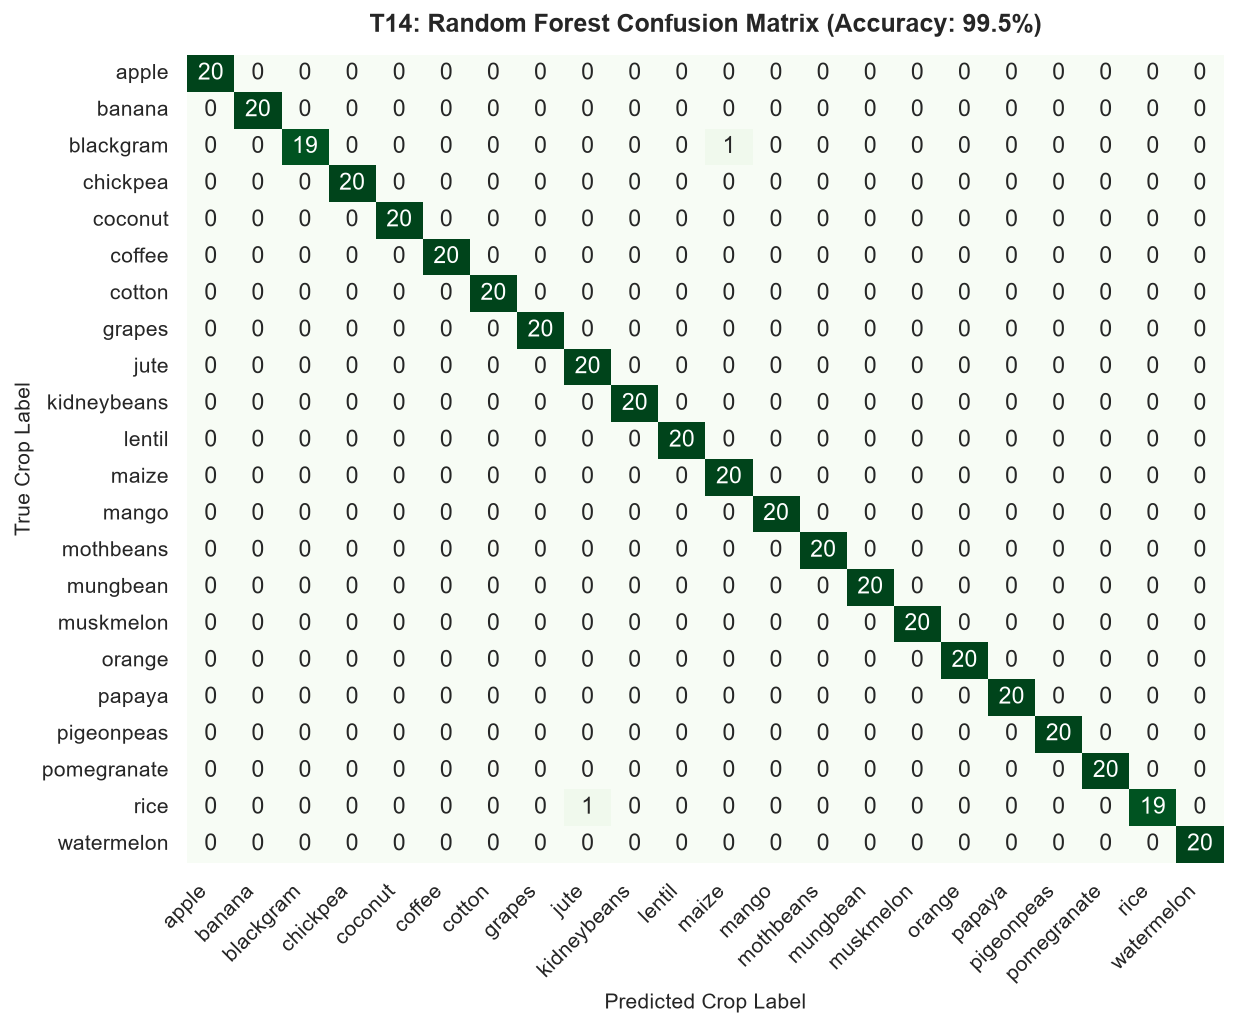

In [5]:
classes = sorted(y.unique())
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=classes)

plt.figure(figsize=(9, 7.5), dpi=140)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=classes, yticklabels=classes, cbar=False)
plt.title(f'T14: Random Forest Confusion Matrix (Accuracy: {rf_test_acc:.1%})', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicted Crop Label', fontsize=11)
plt.ylabel('True Crop Label', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Step 6: Feature Importance Comparison: Decision Tree vs Random Forest

,Single Decision Tree,Random Forest (100 Trees)
N,0.0608,0.1043
P,0.2388,0.1588
K,0.0645,0.1823
temperature,0.0000,0.0707
humidity,0.1910,0.2191
ph,0.0000,0.0451
rainfall,0.4450,0.2199


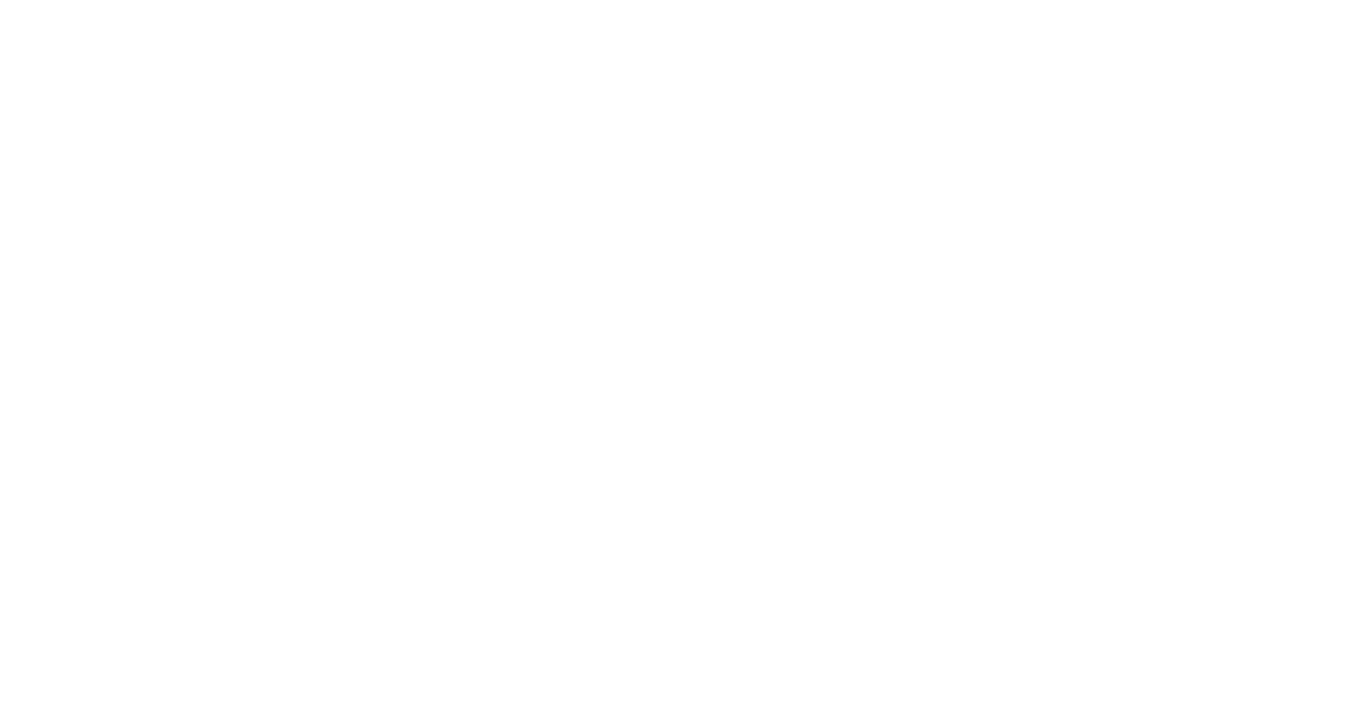

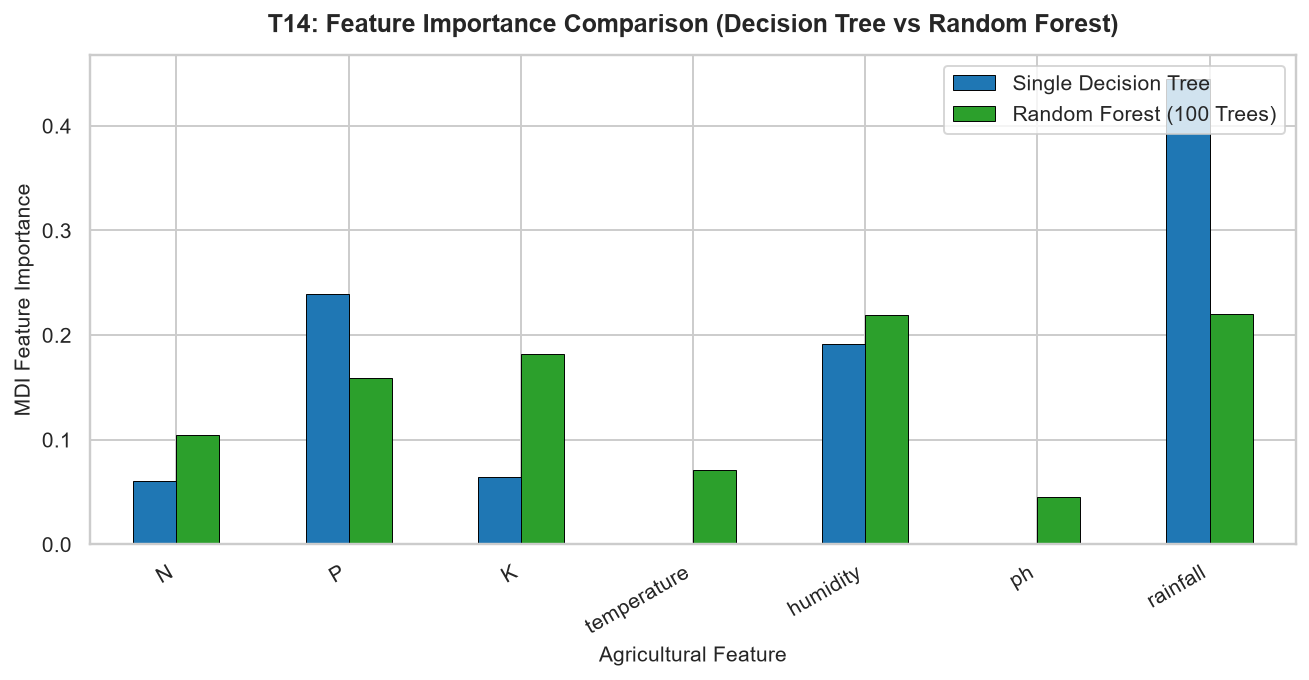

In [6]:
dt = DecisionTreeClassifier(max_depth=7, random_state=42)
dt.fit(X_train, y_train)

df_fi = pd.DataFrame({
    'Single Decision Tree': dt.feature_importances_,
    'Random Forest (100 Trees)': rf.feature_importances_
}, index=features)

plt.figure(figsize=(9.5, 5), dpi=140)
df_fi.plot(kind='bar', figsize=(9.5, 5), color=['#1f77b4', '#2ca02c'], edgecolor='black', linewidth=0.5)
plt.title('T14: Feature Importance Comparison (Decision Tree vs Random Forest)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Agricultural Feature', fontsize=11)
plt.ylabel('MDI Feature Importance', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

display(df_fi.round(4))

### 🎓 Viva Voce Questions & Answers (Tutorial 14)

1. **Q: Why does Random Forest achieve higher accuracy and lower variance than a single Decision Tree?**
   - **A:** A single tree has high variance and easily overfits training noise. By taking the majority vote over 100 independently trained bootstrap trees, individual errors cancel out. The random feature subset selection ($m = \sqrt{p}$) ensures the trees are de-correlated, maximizing the variance reduction formula $\frac{1-\rho}{B} \sigma^2$.

2. **Q: What is the Out-of-Bag (OOB) error and how does it replace a cross-validation set?**
   - **A:** In bootstrap sampling with replacement, the probability of any given sample being omitted from a bootstrap sample of size $n$ is $\lim_{n \to \infty} (1 - 1/n)^n = e^{-1} \approx 36.8\%$. Each sample is evaluated only by the trees for which it was left out, providing a built-in cross-validation estimate without needing a separate validation split.

3. **Q: How does Random Forest (Bagging) differ from Gradient Boosting (Boosting)?**
   - **A:** Random Forest builds deep trees in **parallel** to reduce variance. Gradient Boosting builds shallow trees **sequentially**, with each tree learning from the residual errors (pseudo-residuals) of prior trees to reduce bias.